# Лабораторная работа №5. Исследование градиентного бустинга

| Задача | Датасет | Модель |
|---|---|---|
| Классификация | GTZAN — жанр по аудиопризнакам (10 классов) | `GradientBoostingClassifier` |
| Регрессия | YearPredictionMSD — год выпуска песни | `GradientBoostingRegressor` |

Датасеты, разбиения и метрики те же, что в ЛР1–ЛР4: **macro-F1** для классификации и **MAE** в годах для регрессии.

**План**
1. Коротко о модели.
2. Бейзлайн — бустинг из sklearn с параметрами по умолчанию.
3. Гипотезы, их проверка на кросс-валидации и улучшенный бейзлайн.
4. Своя реализация градиентного бустинга и сравнение с пп. 2 и 3.
5. Итоги по всем пяти работам. Подробное сравнение вынесено в отдельный ноутбук `summary.ipynb`.

Импорты и настройки

In [1]:
import json, sys, time, heapq, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import TransformedTargetRegressor
from sklearn.cross_decomposition import PLSRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import (GradientBoostingClassifier, GradientBoostingRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, mean_absolute_error
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold, cross_val_score
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
from src.data import RANDOM_STATE, download_data, gtzan_split, msd_split
from src.results import RESULTS_DIR, classification_metrics, regression_metrics, save_results

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)
np.random.seed(RANDOM_STATE)

Данные с теми же разбиениями, что и раньше

In [2]:
download_data()
Xc_train, Xc_test, yc_train, yc_test, gc_train, gc_test = gtzan_split()
Xr_train, Xr_test, yr_train, yr_test = msd_split()
print("GTZAN train/test:", Xc_train.shape, Xc_test.shape)
print("MSD   train/test:", Xr_train.shape, Xr_test.shape)

GTZAN train/test: (7993, 57) (1997, 57)
MSD   train/test: (50000, 90) (10000, 90)


## 1. Коротко о модели

Бустинг строит ансамбль последовательно. Модель начинается с константы $F_0$, затем на каждом шаге добавляется небольшое дерево:

$$F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x),$$

где $h_m$ обучается на антиградиенте функции потерь по текущим прогнозам, а $\eta$ — темп обучения (learning rate). Для MSE антиградиент — это просто остатки $y - F_{m-1}(x)$: каждое новое дерево учится исправлять ошибки предыдущих. Для классификации на $K$ классов на каждом шаге строится $K$ деревьев, по одному на логит каждого класса, а вероятности получаются через softmax.

Чем это отличается от случайного леса:
* лес усредняет независимые глубокие деревья и уменьшает в основном **дисперсию**;
* бустинг складывает зависимые неглубокие деревья и уменьшает **смещение**: каждое дерево слабое, но вместе они аппроксимируют сложную функцию;
* поэтому у бустинга, в отличие от леса, большое число деревьев может привести к переобучению. Темп обучения и число итераций нужно подбирать вместе.

В sklearn есть две реализации:
* `GradientBoosting*` — классическая. Деревья глубиной 3, пороги ищутся точно, работает медленно;
* `HistGradientBoosting*` — гистограммная, как LightGBM. Признаки заранее разбиваются на 255 интервалов (бинов), деревья растут «лист за листом» до 31 листа, есть L2-регуляризация. Работает в разы быстрее.

## 2. Бейзлайн

Бейзлайн — `GradientBoostingClassifier` и `GradientBoostingRegressor` с параметрами по умолчанию: 100 деревьев глубины 3, темп 0.1, исходные признаки.

Обучаем бейзлайн и замеряем время

In [3]:
results = {"classification": {}, "regression": {}}
fit_time = {}
t0 = time.time(); base_clf = GradientBoostingClassifier(random_state=RANDOM_STATE).fit(Xc_train, yc_train); fit_time["GTZAN"] = time.time() - t0
t0 = time.time(); base_reg = GradientBoostingRegressor(random_state=RANDOM_STATE).fit(Xr_train, yr_train); fit_time["MSD"] = time.time() - t0
results["classification"]["sklearn baseline"] = classification_metrics(yc_test, base_clf.predict(Xc_test))
results["regression"]["sklearn baseline"] = regression_metrics(yr_test, base_reg.predict(Xr_test))
print(f"Время обучения: GTZAN {fit_time['GTZAN']:.0f} c, MSD {fit_time['MSD']:.0f} c")
pd.DataFrame(results["classification"]).T, pd.DataFrame(results["regression"]).T

Время обучения: GTZAN 105 c, MSD 157 c


(                  accuracy  f1_macro
 sklearn baseline    0.6855    0.6851,
                      MAE    RMSE      R2
 sklearn baseline  6.7307  9.4331  0.2494)

Уже с настройками по умолчанию бустинг получается сильным. На GTZAN он на уровне улучшенных KNN и логистической регрессии, на MSD — лучше всех бейзлайнов из предыдущих работ. При этом обучение долгое: в классификации это 100 итераций × 10 классов = 1000 деревьев с точным поиском порогов.

## 3. Улучшение бейзлайна

### 3.1. Гипотезы

| № | Гипотеза | Задача |
|---|---|---|
| Г1 | Гистограммный бустинг (`HistGradientBoosting*`) будет не хуже классического и намного быстрее, а это позволит перебрать больше вариантов | обе |
| Г2 | Меньший темп обучения при большем числе итераций даст лучшее качество | обе |
| Г3 | Сложность деревьев (`max_leaf_nodes`, `min_samples_leaf`) и L2-регуляризация листьев влияют на качество | обе |
| Г4 | Признаки-проекции LDA и PLS помогут и бустингу | обе |
| Г5 | Для MAE лучше подойдёт обучение на `log(2012 − year)` или функция потерь `absolute_error` вместо MSE | регрессия |

Проверка на тех же фолдах кросс-валидации, что и раньше (`GroupKFold` по трекам для GTZAN).

Функции оценки на кросс-валидации

In [4]:
cv_c = GroupKFold(n_splits=5)
cv_r = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_clf(model):
    return cross_val_score(model, Xc_train, yc_train, cv=cv_c, groups=gc_train, scoring="f1_macro", n_jobs=1).mean()

def cv_reg(model):
    return -cross_val_score(model, Xr_train, yr_train, cv=cv_r, scoring="neg_mean_absolute_error", n_jobs=1).mean()

HGC = lambda **kw: HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE, **kw)
HGR = lambda **kw: HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_STATE, **kw)
hyp_c = {"бейзлайн": cv_clf(GradientBoostingClassifier(random_state=RANDOM_STATE))}
hyp_r = {"бейзлайн": cv_reg(GradientBoostingRegressor(random_state=RANDOM_STATE))}

#### Г1. Гистограммный бустинг

HistGradientBoosting с параметрами по умолчанию (100 итераций, темп 0.1, до 31 листа в дереве)

In [5]:
t0 = time.time(); hyp_c["Г1: HistGradientBoosting"] = cv_clf(HGC()); t_c = time.time() - t0
t0 = time.time(); hyp_r["Г1: HistGradientBoosting"] = cv_reg(HGR()); t_r = time.time() - t0
print(f"Время 5 фолдов: GTZAN {t_c:.0f} c, MSD {t_r:.0f} c")
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

Время 5 фолдов: GTZAN 21 c, MSD 5 c


,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн,0.7019,6.5818
Г1: HistGradientBoosting,0.7358,6.3717


**Г1 подтвердилась.** Гистограммный бустинг лучше в обеих задачах и обучается в разы быстрее. Качество выросло не из-за бинов как таковых: деревья по умолчанию здесь крупнее (31 лист вместо 8 при глубине 3), и каждое из них исправляет больше ошибок. Скорость получается за счёт того, что поиск порога идёт по 255 бинам, а не по всем уникальным значениям. Дальше работаем с `HistGradientBoosting*`.

#### Г2. Темп обучения и число итераций

Кривые качества по итерациям на одном фолде: staged_predict выдаёт прогноз после каждой итерации

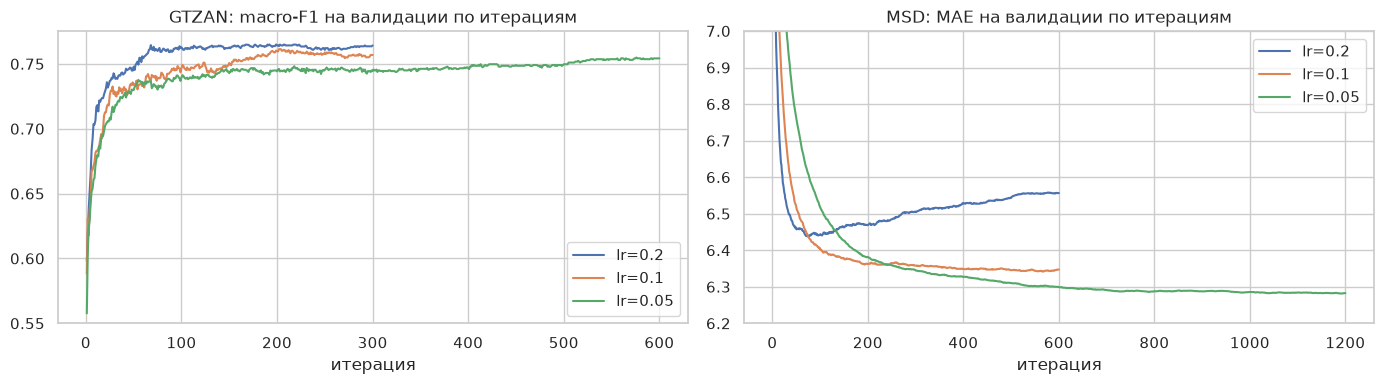

In [6]:
tr_c, va_c = next(cv_c.split(Xc_train, yc_train, gc_train))
tr_r, va_r = next(cv_r.split(Xr_train))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for lr, n in [(0.2, 300), (0.1, 300), (0.05, 600)]:
    m = HGC(learning_rate=lr, max_iter=n).fit(Xc_train.iloc[tr_c], yc_train[tr_c])
    scores = [f1_score(yc_train[va_c], p, average="macro") for p in m.staged_predict(Xc_train.iloc[va_c])]
    axes[0].plot(range(1, n + 1), scores, label=f"lr={lr}")
    m = HGR(learning_rate=lr, max_iter=2 * n).fit(Xr_train.iloc[tr_r], yr_train[tr_r])
    maes = [mean_absolute_error(yr_train[va_r], p) for p in m.staged_predict(Xr_train.iloc[va_r])]
    axes[1].plot(range(1, 2 * n + 1), maes, label=f"lr={lr}")
axes[0].set_title("GTZAN: macro-F1 на валидации по итерациям"); axes[0].set_ylim(0.55, None)
axes[1].set_title("MSD: MAE на валидации по итерациям"); axes[1].set_ylim(6.2, 7.0)
for ax in axes: ax.set_xlabel("итерация"); ax.legend()
plt.tight_layout(); plt.show()

То же на полной кросс-валидации для выбранных пар (темп, число итераций)

In [7]:
hyp_c["Г2: lr=0.05, 300 итераций"] = cv_clf(HGC(learning_rate=0.05, max_iter=300))
hyp_r["Г2: lr=0.05, 500 итераций"] = cv_reg(HGR(learning_rate=0.05, max_iter=500))
hyp_r["Г2: lr=0.05, 1000 итераций"] = cv_reg(HGR(learning_rate=0.05, max_iter=1000))
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн,0.7019,6.5818
Г1: HistGradientBoosting,0.7358,6.3717
"Г2: lr=0.05, 300 итераций",0.7420,NaN
"Г2: lr=0.05, 500 итераций",NaN,6.3006
"Г2: lr=0.05, 1000 итераций",NaN,6.2911


**Г2 подтвердилась для регрессии, для классификации — частично.**

На MSD видна типичная картина бустинга. При темпе 0.2 ошибка быстро падает, но уже после ~100 итераций начинает расти — модель переобучается. При темпе 0.05 спуск медленнее, зато минимум ниже и не портится до 1200 итераций: каждое дерево вносит маленькую поправку, и ансамбль аккуратнее подстраивается под данные.

На GTZAN переобучения в пределах 300–600 итераций не видно ни при каком темпе: все кривые выходят на плато. На этом фолде больший темп даже чуть лучше. Прирост на кросс-валидации здесь в основном от числа итераций: 100 итераций по умолчанию явно мало для 10 классов.

Для подбора остальных параметров дальше берём темп 0.05: 300 итераций для GTZAN и 1000 для MSD.

#### Г3. Сложность деревьев и регуляризация

Меняем размер деревьев и L2-регуляризацию листьев при выбранных темпе и числе итераций

In [8]:
for leaves in [15, 63]:
    hyp_c[f"Г3: max_leaf_nodes={leaves}"] = cv_clf(HGC(learning_rate=0.05, max_iter=300, max_leaf_nodes=leaves))
    hyp_r[f"Г3: max_leaf_nodes={leaves}"] = cv_reg(HGR(learning_rate=0.05, max_iter=1000, max_leaf_nodes=leaves))
hyp_c["Г3: l2_regularization=1"] = cv_clf(HGC(learning_rate=0.05, max_iter=300, l2_regularization=1.0))
hyp_r["Г3: min_samples_leaf=100"] = cv_reg(HGR(learning_rate=0.05, max_iter=1000, min_samples_leaf=100))
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн,0.7019,6.5818
Г1: HistGradientBoosting,0.7358,6.3717
"Г2: lr=0.05, 300 итераций",0.7420,NaN
Г3: max_leaf_nodes=15,0.7395,6.3123
Г3: max_leaf_nodes=63,0.7394,6.2658
Г3: l2_regularization=1,0.7377,NaN
"Г2: lr=0.05, 500 итераций",NaN,6.3006
"Г2: lr=0.05, 1000 итераций",NaN,6.2911
Г3: min_samples_leaf=100,NaN,6.2835


**Г3: эффект небольшой.** Разница между вариантами здесь — сотые доли macro-F1 и сотые доли года MAE, это сравнимо с разбросом между фолдами. После подбора темпа и числа итераций бустинг уже неплохо сбалансирован, и размер деревьев влияет слабо. Эти параметры всё равно включим в сетку в п. 3.2, но больших изменений от них не ждём.

#### Г4. Признаки LDA и PLS

Те же конструкторы признаков, что в ЛР3–ЛР4: исходные признаки плюс 9 компонент LDA или k компонент PLS.

In [9]:
class PLSFeatures(BaseEstimator, TransformerMixin):
    """Компоненты PLS как обычный трансформер (PLSRegression.fit_transform возвращает пару массивов)."""

    def __init__(self, n_components=10):
        self.n_components = n_components

    def fit(self, X, y):
        self.pls_ = PLSRegression(n_components=self.n_components, scale=False).fit(X, y)
        return self

    def transform(self, X):
        return self.pls_.transform(X)


def with_lda():
    return FeatureUnion([("orig", FunctionTransformer()), ("lda", LinearDiscriminantAnalysis())])


def with_pls(k=10):
    return FeatureUnion([("orig", FunctionTransformer()), ("pls", Pipeline([("sc", StandardScaler()), ("pls", PLSFeatures(k))]))])

Бустинг на исходных признаках + проекциях

In [10]:
hyp_c["Г4: + LDA"] = cv_clf(Pipeline([("feat", with_lda()), ("gb", HGC(learning_rate=0.05, max_iter=300))]))
hyp_r["Г4: + PLS(10)"] = cv_reg(Pipeline([("feat", with_pls(10)), ("gb", HGR(learning_rate=0.05, max_iter=1000))]))
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн,0.7019,6.5818
Г1: HistGradientBoosting,0.7358,6.3717
"Г2: lr=0.05, 300 итераций",0.7420,NaN
Г3: max_leaf_nodes=15,0.7395,6.3123
Г3: max_leaf_nodes=63,0.7394,6.2658
Г3: l2_regularization=1,0.7377,NaN
Г4: + LDA,0.7423,NaN
"Г2: lr=0.05, 500 итераций",NaN,6.3006
"Г2: lr=0.05, 1000 итераций",NaN,6.2911
Г3: min_samples_leaf=100,NaN,6.2835


В классификации LDA-признаки бустингу практически ничего не дают, разница в четвёртом знаке. В регрессии PLS-признаки снижают MAE примерно на 0.07 года. Вероятное объяснение такое. На каждой итерации бустинг строит по дереву на класс и сам набирает нужные комбинации признаков. А год выпуска связан с тембром во многом линейно, и такую зависимость деревья даже в бустинге аппроксимируют «ступеньками» — готовые линейные проекции им помогают.

#### Г5. Функция потерь для регрессии

Сравниваем MSE на исходном таргете, MSE на log(2012 - year) и прямую оптимизацию MAE (absolute_error)

In [11]:
log_y = lambda y: np.log(2012 - y)
exp_y = lambda z: 2012 - np.exp(z)
log_target = lambda model: TransformedTargetRegressor(regressor=model, func=log_y, inverse_func=exp_y)
hyp_r["Г5: loss=absolute_error"] = cv_reg(HGR(loss="absolute_error", learning_rate=0.05, max_iter=1000))
hyp_r["Г5: log-таргет"] = cv_reg(log_target(HGR(learning_rate=0.05, max_iter=1000)))
hyp_r["Г4+Г5: + PLS(10), log-таргет"] = cv_reg(log_target(Pipeline([("feat", with_pls(10)), ("gb", HGR(learning_rate=0.05, max_iter=1000))])))
pd.Series(hyp_r, name="MSD MAE ↓").to_frame()

,MSD MAE ↓
бейзлайн,6.5818
Г1: HistGradientBoosting,6.3717
"Г2: lr=0.05, 500 итераций",6.3006
"Г2: lr=0.05, 1000 итераций",6.2911
Г3: max_leaf_nodes=15,6.3123
Г3: max_leaf_nodes=63,6.2658
Г3: min_samples_leaf=100,6.2835
Г4: + PLS(10),6.2234
Г5: loss=absolute_error,6.0682
Г5: log-таргет,6.0628


**Г4 и Г5.** Смена функции потерь даёт заметный выигрыш. Обучение на `log(2012 − year)` и прямая оптимизация `absolute_error` получаются почти одинаковыми: обе убирают влияние длинного хвоста старых записей, ради которого MSE «жертвует» основной массой песен. Дальше используем логарифм — он работает и с моей реализацией, где есть только квадратичная потеря.

Вместе с PLS-признаками логарифм таргета даёт лучший результат.

### 3.2. Подбор параметров и улучшенный бейзлайн

Сетка небольшая, потому что каждая точка для GTZAN занимает около минуты:
* **классификация** (темп 0.05, 300 итераций): признаки (исходные / + LDA), `max_leaf_nodes`, `l2_regularization`;
* **регрессия** (темп 0.05, 1000 итераций, логарифм таргета): признаки (исходные / + PLS), `max_leaf_nodes`, `min_samples_leaf`.

Сетка для классификации

In [12]:
grid_c = GridSearchCV(Pipeline([("feat", "passthrough"), ("gb", HGC(learning_rate=0.05, max_iter=300))]), {
    "feat": ["passthrough", with_lda()],
    "gb__max_leaf_nodes": [15, 31],
    "gb__l2_regularization": [0.0, 1.0],
}, cv=cv_c, scoring="f1_macro", n_jobs=1)
t0 = time.time(); grid_c.fit(Xc_train, yc_train, groups=gc_train)
print(f"{time.time() - t0:.0f} c | {grid_c.best_params_} | CV macro-F1 = {grid_c.best_score_:.4f}")
hyp_c["GridSearchCV"] = grid_c.best_score_

343 c | {'feat': FeatureUnion(transformer_list=[('orig', FunctionTransformer()),
                               ('lda', LinearDiscriminantAnalysis())]), 'gb__l2_regularization': 0.0, 'gb__max_leaf_nodes': 31} | CV macro-F1 = 0.7423


Сетка для регрессии

In [13]:
grid_r = GridSearchCV(log_target(Pipeline([("feat", "passthrough"), ("gb", HGR(learning_rate=0.05, max_iter=1000))])), {
    "regressor__feat": ["passthrough", with_pls(10)],
    "regressor__gb__max_leaf_nodes": [15, 31, 63],
    "regressor__gb__min_samples_leaf": [20, 100],
}, cv=cv_r, scoring="neg_mean_absolute_error", n_jobs=1)
t0 = time.time(); grid_r.fit(Xr_train, yr_train)
print(f"{time.time() - t0:.0f} c | {grid_r.best_params_} | CV MAE = {-grid_r.best_score_:.4f}")
hyp_r["GridSearchCV"] = -grid_r.best_score_

425 c | {'regressor__feat': FeatureUnion(transformer_list=[('orig', FunctionTransformer()),
                               ('pls',
                                Pipeline(steps=[('sc', StandardScaler()),
                                                ('pls', PLSFeatures())]))]), 'regressor__gb__max_leaf_nodes': 63, 'regressor__gb__min_samples_leaf': 100} | CV MAE = 5.9834


Сводка по всем гипотезам

In [14]:
pd.concat([pd.Series(hyp_c, name="GTZAN CV macro-F1 ↑"), pd.Series(hyp_r, name="MSD CV MAE ↓")], axis=1)

,GTZAN CV macro-F1 ↑,MSD CV MAE ↓
бейзлайн,0.7019,6.5818
Г1: HistGradientBoosting,0.7358,6.3717
"Г2: lr=0.05, 300 итераций",0.7420,NaN
Г3: max_leaf_nodes=15,0.7395,6.3123
Г3: max_leaf_nodes=63,0.7394,6.2658
Г3: l2_regularization=1,0.7377,NaN
Г4: + LDA,0.7423,NaN
GridSearchCV,0.7423,5.9834
"Г2: lr=0.05, 500 итераций",NaN,6.3006
"Г2: lr=0.05, 1000 итераций",NaN,6.2911


Улучшенный бейзлайн: лучшие конвейеры (GridSearchCV уже переобучил их на всём train), оценка на test

In [15]:
best_clf, best_reg = grid_c.best_estimator_, grid_r.best_estimator_
yc_pred_best, yr_pred_best = best_clf.predict(Xc_test), best_reg.predict(Xr_test)
results["classification"]["sklearn improved"] = classification_metrics(yc_test, yc_pred_best)
results["regression"]["sklearn improved"] = regression_metrics(yr_test, yr_pred_best)
pd.DataFrame(results["classification"]).T, pd.DataFrame(results["regression"]).T

(                  accuracy  f1_macro
 sklearn baseline    0.6855    0.6851
 sklearn improved    0.7266    0.7252,
                      MAE    RMSE      R2
 sklearn baseline  6.7307  9.4331  0.2494
 sklearn improved  6.1019  9.4001  0.2546)

Матрица ошибок и «прогноз против факта»

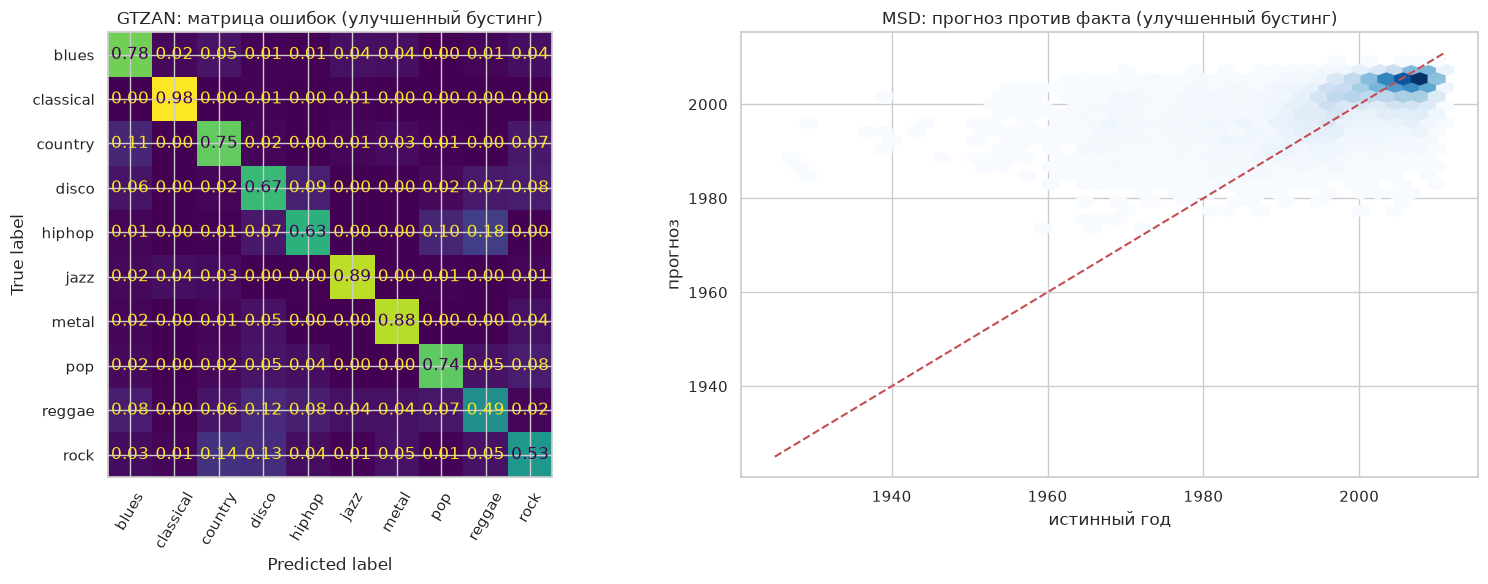

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred_best, normalize="true", values_format=".2f", ax=axes[0], colorbar=False, xticks_rotation=60)
axes[0].set_title("GTZAN: матрица ошибок (улучшенный бустинг)")
axes[1].hexbin(yr_test, yr_pred_best, gridsize=40, cmap="Blues", mincnt=1, extent=(1925, 2011, 1925, 2011))
axes[1].plot([1925, 2011], [1925, 2011], "r--"); axes[1].set_xlabel("истинный год"); axes[1].set_ylabel("прогноз")
axes[1].set_title("MSD: прогноз против факта (улучшенный бустинг)")
plt.tight_layout(); plt.show()

**Итог по улучшению.** В классификации помогли переход на гистограммный бустинг с более крупными деревьями и больше итераций. В сетке LDA-признаки формально выиграли, но с разницей в пределах шума. В регрессии к этому добавились обучение на логарифме таргета, PLS-признаки и чуть более крупные деревья (63 листа, не меньше 100 песен в листе). Как и в ЛР2–ЛР4, логарифм таргета снижает MAE. Здесь RMSE при этом тоже не ухудшился.

## 4. Своя реализация

### 4.1. Как устроено

Я реализовал гистограммный вариант, как в `HistGradientBoosting` и LightGBM: на точном поиске порогов 1000 итераций по 50 000 объектам считались бы слишком долго.

**Бинирование (`Binner`).** Для каждого признака по обучающей выборке считаются границы бинов: квантили, если уникальных значений больше 255, иначе середины между соседними значениями. Дальше вся работа идёт с матрицей номеров бинов типа `uint8`.

**Дерево (`HistTree`).** Каждому объекту соответствуют градиент $g_i$ и гессиан $h_i$ функции потерь по текущему прогнозу.
* Для узла строятся гистограммы: суммы $g$, $h$ и число объектов в каждом бине каждого признака. Это одна `np.bincount` по всем признакам сразу.
* Накопленными суммами по бинам получаются статистики левой и правой части для всех порогов, и выбирается порог с наибольшим выигрышем:
$$\text{gain} = \frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{G^2}{H + \lambda}.$$
* Значение в листе — ньютоновский шаг $-G/(H + \lambda)$.
* Дерево растёт «лист за листом»: из всех текущих листьев делится тот, у которого выигрыш больше. Для этого нужна очередь с приоритетом (`heapq`). Рост останавливается на `max_leaf_nodes` листьях или на `max_depth`.
* Гистограмма считается заново только для меньшего из двух потомков, а для большего получается вычитанием из гистограммы родителя. Это стандартный приём, который почти вдвое сокращает работу.

**Функции потерь.**
* Регрессия, MSE: $g = F - y$, $h = 1$; начальный прогноз — среднее.
* Классификация, softmax: $g_k = p_k - y_k$, $h_k = p_k(1 - p_k)$; начальный прогноз — логарифмы долей классов. На каждой итерации строится по дереву на класс.

Код реализации. Несколько деталей:
* в `HistTree` к номеру бина прибавляется смещение `j * n_bins`, чтобы одна `np.bincount` посчитала гистограммы всех признаков сразу;
* в очереди с приоритетом лежат кандидаты на деление вместе с уже найденным лучшим разбиением и гистограммой узла. Счётчик `counter` нужен, чтобы `heapq` никогда не сравнивал сами массивы при равном выигрыше;
* `decision_function` возвращает «сырые» прогнозы (для классификации — логиты), а `predict` превращает их в ответ.

In [17]:
class Binner:
    """Переводит признаки в номера бинов (не больше max_bins бинов на признак)."""

    def __init__(self, max_bins=255):
        self.max_bins = max_bins

    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        qs = np.linspace(0, 100, self.max_bins + 1)[1:-1]
        self.edges_ = []
        for j in range(X.shape[1]):
            u = np.unique(X[:, j])
            edges = (u[:-1] + u[1:]) / 2 if len(u) <= self.max_bins else np.unique(np.percentile(X[:, j], qs, method="midpoint"))
            self.edges_.append(edges)
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=np.float64)
        return np.column_stack([np.searchsorted(e, X[:, j]) for j, e in enumerate(self.edges_)]).astype(np.uint8)


class HistTree:
    """Дерево на гистограммах градиентов, растущее по наибольшему выигрышу."""

    def __init__(self, max_leaf_nodes=31, max_depth=None, min_samples_leaf=20, l2=0.0, n_bins=256):
        self.max_leaf_nodes, self.max_depth = max_leaf_nodes, max_depth
        self.min_samples_leaf, self.l2, self.n_bins = min_samples_leaf, l2, n_bins

    def _hist(self, B, g, h, idx):
        d, nb = B.shape[1], self.n_bins
        flat = (B[idx] + self.offsets_).ravel()
        G = np.bincount(flat, weights=np.repeat(g[idx], d), minlength=d * nb).reshape(d, nb)
        H = np.bincount(flat, weights=np.repeat(h[idx], d), minlength=d * nb).reshape(d, nb)
        N = np.bincount(flat, minlength=d * nb).reshape(d, nb)
        return G, H, N

    def _best_split(self, G, H, N):
        Gt, Ht, Nt = G[0].sum(), H[0].sum(), N[0].sum()
        GL, HL, NL = np.cumsum(G, 1)[:, :-1], np.cumsum(H, 1)[:, :-1], np.cumsum(N, 1)[:, :-1]
        GR, HR, NR = Gt - GL, Ht - HL, Nt - NL
        lam, eps = self.l2, 1e-12
        gain = GL ** 2 / (HL + lam + eps) + GR ** 2 / (HR + lam + eps) - Gt ** 2 / (Ht + lam + eps)
        gain = np.where((NL >= self.min_samples_leaf) & (NR >= self.min_samples_leaf), gain, -np.inf)
        f, b = np.unravel_index(np.argmax(gain), gain.shape)
        return gain[f, b], int(f), int(b)

    def fit(self, B, g, h):
        self.offsets_ = np.arange(B.shape[1], dtype=np.int64) * self.n_bins
        self.feature, self.bin, self.left, self.right, self.value = [], [], [], [], []
        heap, counter = [], 0

        def new_node(idx):
            self.feature.append(-1); self.bin.append(0); self.left.append(-1); self.right.append(-1)
            self.value.append(-g[idx].sum() / (h[idx].sum() + self.l2))
            return len(self.feature) - 1

        def push(node, idx, hist, depth):
            nonlocal counter
            if len(idx) < 2 * self.min_samples_leaf or (self.max_depth is not None and depth >= self.max_depth):
                return
            gain, f, b = self._best_split(*hist)
            if gain > 1e-12:
                heapq.heappush(heap, (-gain, counter, node, idx, hist, depth, f, b))
                counter += 1

        root = np.arange(len(B))
        push(new_node(root), root, self._hist(B, g, h, root), 0)
        n_leaves = 1
        while heap and (self.max_leaf_nodes is None or n_leaves < self.max_leaf_nodes):
            _, _, node, idx, hist, depth, f, b = heapq.heappop(heap)
            to_left = B[idx, f] <= b
            li, ri = idx[to_left], idx[~to_left]
            small = li if len(li) <= len(ri) else ri
            hist_small = self._hist(B, g, h, small)
            hist_large = tuple(p - s for p, s in zip(hist, hist_small))
            hist_l, hist_r = (hist_small, hist_large) if small is li else (hist_large, hist_small)
            self.feature[node], self.bin[node] = f, b
            self.left[node], self.right[node] = new_node(li), new_node(ri)
            n_leaves += 1
            push(self.left[node], li, hist_l, depth + 1)
            push(self.right[node], ri, hist_r, depth + 1)
        self.feature, self.bin = np.array(self.feature), np.array(self.bin)
        self.left, self.right, self.value = np.array(self.left), np.array(self.right), np.array(self.value)
        return self

    def predict(self, B):
        node = np.zeros(len(B), dtype=np.int64)
        active = self.feature[node] >= 0
        while active.any():
            a = np.where(active)[0]
            to_left = B[a, self.feature[node[a]]] <= self.bin[node[a]]
            node[a] = np.where(to_left, self.left[node[a]], self.right[node[a]])
            active[a] = self.feature[node[a]] >= 0
        return self.value[node]


class MyGradientBoosting:
    """Градиентный бустинг на HistTree: MSE для регрессии, softmax для классификации."""

    def __init__(self, task="regression", n_estimators=100, learning_rate=0.1, max_leaf_nodes=31, max_depth=None,
                 min_samples_leaf=20, l2_regularization=0.0, max_bins=255):
        self.task, self.n_estimators, self.learning_rate = task, n_estimators, learning_rate
        self.max_leaf_nodes, self.max_depth, self.min_samples_leaf = max_leaf_nodes, max_depth, min_samples_leaf
        self.l2_regularization, self.max_bins = l2_regularization, max_bins

    def _new_tree(self):
        return HistTree(self.max_leaf_nodes, self.max_depth, self.min_samples_leaf, self.l2_regularization, self.max_bins + 1)

    @staticmethod
    def _softmax(F):
        E = np.exp(F - F.max(axis=1, keepdims=True))
        return E / E.sum(axis=1, keepdims=True)

    def fit(self, X, y):
        self.binner_ = Binner(self.max_bins).fit(X)
        B = self.binner_.transform(X)
        self.trees_ = []
        if self.task == "regression":
            y = np.asarray(y, dtype=np.float64)
            self.init_ = y.mean()
            F, ones = np.full(len(y), self.init_), np.ones(len(y))
            for _ in range(self.n_estimators):
                tree = self._new_tree().fit(B, F - y, ones)
                F += self.learning_rate * tree.predict(B)
                self.trees_.append(tree)
        else:
            self.classes_, codes = np.unique(y, return_inverse=True)
            Y = np.eye(len(self.classes_))[codes]
            log_prior = np.log(Y.mean(axis=0))
            self.init_ = log_prior - log_prior.mean()
            F = np.tile(self.init_, (len(Y), 1))
            for _ in range(self.n_estimators):
                P = self._softmax(F)
                stage = []
                for k in range(len(self.classes_)):
                    tree = self._new_tree().fit(B, P[:, k] - Y[:, k], P[:, k] * (1 - P[:, k]))
                    F[:, k] += self.learning_rate * tree.predict(B)
                    stage.append(tree)
                self.trees_.append(stage)
        return self

    def decision_function(self, X):
        B = self.binner_.transform(X)
        if self.task == "regression":
            return self.init_ + self.learning_rate * np.sum([t.predict(B) for t in self.trees_], axis=0)
        F = np.tile(self.init_, (len(B), 1))
        for stage in self.trees_:
            for k, tree in enumerate(stage):
                F[:, k] += self.learning_rate * tree.predict(B)
        return F

    def predict(self, X):
        F = self.decision_function(X)
        return F if self.task == "regression" else self.classes_[F.argmax(axis=1)]

Сравнение с HistGradientBoosting из sklearn при одинаковых параметрах (100 итераций, темп 0.1, 31 лист)

In [18]:
rows = []
for name, X_tr, y_tr, X_te, y_te, task in [("GTZAN", Xc_train, yc_train, Xc_test, yc_test, "classification"),
                                           ("MSD", Xr_train, yr_train, Xr_test, yr_test, "regression")]:
    Sk = HGC if task == "classification" else HGR
    metric = (lambda y, p: f1_score(y, p, average="macro")) if task == "classification" else mean_absolute_error
    t0 = time.time(); sk = Sk().fit(X_tr, y_tr); t_sk = time.time() - t0
    t0 = time.time(); my = MyGradientBoosting(task).fit(X_tr, y_tr); t_my = time.time() - t0
    p_sk, p_my = sk.predict(X_te), my.predict(X_te)
    agree = (p_sk == p_my).mean() if task == "classification" else np.corrcoef(p_sk, p_my)[0, 1]
    rows.append({"данные": name, "метрика sklearn": metric(y_te, p_sk), "метрика моя": metric(y_te, p_my),
                 "согласие прогнозов": agree, "время sklearn, c": t_sk, "время моё, c": t_my})
pd.DataFrame(rows)

,данные,метрика sklearn,метрика моя,согласие прогнозов,"время sklearn, c","время моё, c"
0,GTZAN,0.7155,0.7185,0.9199,3.8149,24.6281
1,MSD,6.5410,6.5190,0.9708,0.9109,13.0174


Качество на уровне sklearn, а прогнозы сильно согласованы: для классификации это доля совпавших классов, для регрессии — корреляция прогнозов. Точного совпадения ждать не стоит. sklearn строит бины чуть иначе (в частности, по подвыборке для больших данных) и использует несколько дополнительных порогов остановки. Из-за этого на ранних итерациях выбираются немного другие разбиения, а бустинг накапливает такие различия. По скорости моя реализация медленнее: sklearn строит гистограммы параллельно на C, а у меня NumPy в одном потоке.

### 4.2. Своя реализация в условиях бейзлайна (сравнение с п. 2)

Бейзлайн из п. 2 — классический бустинг: деревья глубины 3, без ограничения на размер листа, 100 итераций, темп 0.1. Повторяю эти настройки в своей реализации: `max_depth=3`, `max_leaf_nodes=None`, `min_samples_leaf=1`. Отличие одно: пороги ищутся по бинам, а не точно.

Своя реализация с параметрами бейзлайна

In [19]:
t0 = time.time()
my_base_clf = MyGradientBoosting("classification", n_estimators=100, learning_rate=0.1, max_depth=3, max_leaf_nodes=None, min_samples_leaf=1).fit(Xc_train, yc_train)
results["classification"]["custom baseline"] = classification_metrics(yc_test, my_base_clf.predict(Xc_test))
t1 = time.time()
my_base_reg = MyGradientBoosting("regression", n_estimators=100, learning_rate=0.1, max_depth=3, max_leaf_nodes=None, min_samples_leaf=1).fit(Xr_train, yr_train)
results["regression"]["custom baseline"] = regression_metrics(yr_test, my_base_reg.predict(Xr_test))
print(f"Время: GTZAN {t1 - t0:.0f} c (sklearn {fit_time['GTZAN']:.0f} c), MSD {time.time() - t1:.0f} c (sklearn {fit_time['MSD']:.0f} c)")
cmp = ["sklearn baseline", "custom baseline"]
pd.DataFrame(results["classification"]).T.loc[cmp], pd.DataFrame(results["regression"]).T.loc[cmp]

Время: GTZAN 9 c (sklearn 105 c), MSD 9 c (sklearn 157 c)


(                  accuracy  f1_macro
 sklearn baseline    0.6855    0.6851
 custom baseline     0.6800    0.6804,
                      MAE    RMSE      R2
 sklearn baseline  6.7307  9.4331  0.2494
 custom baseline   6.7160  9.4263  0.2505)

Метрики близки к бейзлайну sklearn. Небольшая разница объясняется двумя вещами: поиском порогов по бинам вместо точного и немного другим шагом в листьях для классификации (в sklearn к ньютоновскому шагу добавляется множитель $(K-1)/K$). При этом моя гистограммная версия обучается быстрее классического `GradientBoosting*`, несмотря на Python — это и есть главный выигрыш бинирования.

### 4.3. Своя реализация с улучшениями (сравнение с п. 3)

Беру те же признаки (LDA / PLS, если они попали в лучший конвейер), логарифм таргета и параметры из сетки.

Признаки — все шаги лучшего конвейера, кроме самого бустинга; параметры — из GridSearchCV

In [20]:
gb_c, gb_r = best_clf[-1], best_reg.regressor_[-1]
Fc_train, Fc_test = best_clf[:-1].transform(Xc_train), best_clf[:-1].transform(Xc_test)
Fr_train, Fr_test = best_reg.regressor_[:-1].transform(Xr_train), best_reg.regressor_[:-1].transform(Xr_test)
same_params = lambda gb: dict(n_estimators=gb.max_iter, learning_rate=gb.learning_rate, max_leaf_nodes=gb.max_leaf_nodes,
                              min_samples_leaf=gb.min_samples_leaf, l2_regularization=gb.l2_regularization)
t0 = time.time()
my_clf = MyGradientBoosting("classification", **same_params(gb_c)).fit(Fc_train, yc_train)
results["classification"]["custom improved"] = classification_metrics(yc_test, my_clf.predict(Fc_test))
t1 = time.time()
my_reg = MyGradientBoosting("regression", **same_params(gb_r)).fit(Fr_train, log_y(yr_train))
results["regression"]["custom improved"] = regression_metrics(yr_test, exp_y(my_reg.predict(Fr_test)))
print(f"Время: GTZAN {t1 - t0:.0f} c, MSD {time.time() - t1:.0f} c")
print("Параметры:", same_params(gb_c), same_params(gb_r))
cmp = ["sklearn improved", "custom improved"]
pd.DataFrame(results["classification"]).T.loc[cmp], pd.DataFrame(results["regression"]).T.loc[cmp]

Время: GTZAN 80 c, MSD 137 c
Параметры: {'n_estimators': 300, 'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 20, 'l2_regularization': 0.0} {'n_estimators': 1000, 'learning_rate': 0.05, 'max_leaf_nodes': 63, 'min_samples_leaf': 100, 'l2_regularization': 0.0}


(                  accuracy  f1_macro
 sklearn improved    0.7266    0.7252
 custom improved     0.7276    0.7251,
                      MAE    RMSE      R2
 sklearn improved  6.1019  9.4001  0.2546
 custom improved   6.1142  9.4355  0.2490)

С улучшениями своя реализация снова выходит на уровень sklearn. Значит, весь прирост из п. 3 переносится на неё: он связан с постановкой (размер деревьев, темп, число итераций, признаки, логарифм таргета), а не с особенностями библиотеки.

## 5. Итоги

Таблицы ЛР5 и сохранение результатов

In [21]:
res_c, res_r = pd.DataFrame(results["classification"]).T, pd.DataFrame(results["regression"]).T
path = save_results("lab5_boosting", results)
print("Результаты сохранены в", path.relative_to(ROOT))
display(res_c.style.highlight_max(color="lightgreen").format("{:.4f}"))
display(res_r.style.highlight_min(subset=["MAE", "RMSE"], color="lightgreen").highlight_max(subset=["R2"], color="lightgreen").format("{:.4f}"))

Результаты сохранены в results/lab5_boosting.json


,accuracy,f1_macro
sklearn baseline,0.6855,0.6851
sklearn improved,0.7266,0.7252
custom baseline,0.6800,0.6804
custom improved,0.7276,0.7251


,MAE,RMSE,R2
sklearn baseline,6.7307,9.4331,0.2494
sklearn improved,6.1019,9.4001,0.2546
custom baseline,6.7160,9.4263,0.2505
custom improved,6.1142,9.4355,0.2490


Лучшие (улучшенные) модели всех пяти работ на тестовой выборке

In [22]:
labs = {"KNN": "lab1_knn", "Линейные модели": "lab2_linear", "Решающее дерево": "lab3_tree",
        "Случайный лес": "lab4_forest", "Градиентный бустинг": "lab5_boosting"}
summary = pd.DataFrame({name: {"GTZAN macro-F1 ↑": r["classification"]["sklearn improved"]["f1_macro"],
                               "MSD MAE ↓": r["regression"]["sklearn improved"]["MAE"],
                               "MSD R² ↑": r["regression"]["sklearn improved"]["R2"]}
                        for name, r in {n: json.loads((RESULTS_DIR / f"{f}.json").read_text()) for n, f in labs.items()}.items()}).T
summary

,GTZAN macro-F1 ↑,MSD MAE ↓,MSD R² ↑
KNN,0.6828,7.0208,0.1805
Линейные модели,0.6763,6.3337,0.2064
Решающее дерево,0.5314,6.4885,0.1807
Случайный лес,0.6909,6.2269,0.2231
Градиентный бустинг,0.7252,6.1019,0.2546


### Выводы

1. **Бейзлайн.** Классический бустинг с настройками по умолчанию сразу работает хорошо, но медленно.
2. **Улучшения.** Больше всего дали:
   * гистограммная реализация с более крупными деревьями;
   * меньший темп обучения при большем числе итераций;
   * логарифм таргета (или функция потерь `absolute_error`) и PLS-признаки для регрессии.

   LDA-признаки, которые сильно помогали дереву и лесу, бустингу в классификации почти ничего не дают. Параметры деревьев и регуляризация влияют в пределах шума.
3. **Своя реализация.** Гистограммный бустинг с ростом деревьев по выигрышу, ньютоновскими шагами и L2-регуляризацией даёт качество на уровне sklearn.
4. **Сравнение с другими алгоритмами.** Подробно — в `summary.ipynb`. Коротко: бустинг — лучшая модель в обеих задачах, хотя отрыв от случайного леса и линейной регрессии на MSD невелик. Год выпуска по тембру предсказывается с ошибкой около 6 лет, и, похоже, это близко к пределу того, что можно извлечь из этих 90 признаков.